In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv("/Users/pasha/Desktop/master/master_thesis/Data/BMG9156K1018_10.09.2026_14.59.34.csv", delimiter=";", decimal=",", low_memory=False)
# Kongsberg Gruppen's replacement ISIN has no CompanyId in the export.
kongsberg_missing_id = data["ISIN"].eq("NO0013536151") & data["CompanyId"].isna()
data.loc[kongsberg_missing_id, "CompanyId"] = 2331
print(f"Imputed Kongsberg Gruppen CompanyId 2331 for {kongsberg_missing_id.sum():,} records.")


Imputed Kongsberg Gruppen CompanyId 2331 for 325 records.


In [ ]:
data.head(10)

,Date,Internal code,SecurityId,CompanyId,Symbol,ISIN,Name,BestBidPrice,BestAskPrice,Open,...,NOWA_DayLnrate,bills_3month_Lnrate,Sector,IN_OSEBX,Equity,Debt,Earnings,debt_ratio,PE,ID
0,2019-07-15,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.05,81.0,83.00,...,0.000055,0.000056,Industrials,0,NaN,NaN,NaN,NaN,NaN,691997
1,2019-07-16,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.55,81.0,81.00,...,0.000055,0.000056,Industrials,0,NaN,NaN,NaN,NaN,NaN,692113
2,2019-07-17,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.40,81.0,81.00,...,0.000055,0.000056,Industrials,0,NaN,NaN,NaN,NaN,NaN,681877
3,2019-07-18,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,77.40,80.0,80.01,...,0.000056,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,681961
4,2019-07-19,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,78.00,79.0,78.00,...,0.000055,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,692452
5,2019-07-22,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,78.00,78.5,80.20,...,0.000055,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,682170
6,2019-07-23,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,78.00,79.0,78.50,...,0.000055,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,682267
7,2019-07-24,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,76.00,78.0,79.00,...,0.000055,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,682384
8,2019-07-25,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,76.99,77.4,78.00,...,0.000055,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,682478
9,2019-07-29,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,76.02,77.0,76.02,...,0.000056,0.000057,Industrials,0,NaN,NaN,NaN,NaN,NaN,693080


In [ ]:
data.columns

Index(['Date', 'Internal code', 'SecurityId', 'CompanyId', 'Symbol', 'ISIN',
       'Name', 'BestBidPrice', 'BestAskPrice', 'Open', 'High', 'Low', 'Close',
       'NumberOfTrades', 'Volume', 'Turnover', 'VolumeWeightedAveragePrice',
       'Price', 'AdjustedPrice', 'Dividends', 'LDividends', 'CorpAdj',
       'DividendAdj', 'Currency', 'NumberOfShares', 'NumberSharesOSEBX',
       'Exchange', 'NOKPerForex', 'mktcap', 'OSEBXmktshare_prevmnth',
       'OSEBXAlpha_prevmnth', 'OSEBXBeta_prevmnth', 'SMB', 'HML', 'LIQ', 'MOM',
       'lnDeltaP', 'lnDeltaOSEBX', 'lnDeltaOBX', 'NOWA_DayLnrate',
       'bills_3month_Lnrate', 'Sector', 'IN_OSEBX', 'Equity', 'Debt',
       'Earnings', 'debt_ratio', 'PE', 'ID'],
      dtype='object')

In [ ]:
company_data = data[["CompanyId", "Name", "ISIN", "Date", "AdjustedPrice", "Volume", "mktcap"]].copy()
company_data["Name"] = company_data["Name"].str.strip()
company_data["Date"] = pd.to_datetime(company_data["Date"], format="%Y-%m-%d")
missing_company_ids = company_data["CompanyId"].isna().sum()
company_data = company_data.dropna(subset=["CompanyId"])
company_data["CompanyId"] = company_data["CompanyId"].astype("int64")
company_data = company_data.sort_values(["CompanyId", "Date"], kind="stable")
companies = company_data.groupby("CompanyId", sort=True)

company_summary = companies.agg(
    latest_name=("Name", "last"),
    start_date=("Date", "min"),
    end_date=("Date", "max"),
    observations=("Date", "size"),
    available_adjusted_prices=("AdjustedPrice", "count"),
    securities=("ISIN", "nunique"),
    total_volume=("Volume", lambda volume: volume.sum(min_count=1)),
)
company_summary["span_years"] = (
    company_summary["end_date"] - company_summary["start_date"]
).dt.days / 365.25

start_date = pd.to_datetime(data["Date"]).min()
end_date = pd.to_datetime(data["Date"]).max()
span_years = (end_date - start_date).days / 365.25

# Require a usable adjusted price at the dataset endpoint; retain full history.
endpoint_records = company_data.loc[company_data["Date"].eq(end_date)]
active_company_ids = endpoint_records.loc[
    endpoint_records["AdjustedPrice"].notna() & endpoint_records["AdjustedPrice"].ne(0), "CompanyId"
].unique()
# Market caps are per security in NOK; count each ISIN once, then sum share classes.
endpoint_market_caps = (
    endpoint_records.loc[endpoint_records["mktcap"].gt(0)]
    .drop_duplicates(["CompanyId", "ISIN"])
    .groupby("CompanyId")["mktcap"].sum(min_count=1)
    .rename("market_cap")
)
company_summary = (
    company_summary.loc[company_summary.index.isin(active_company_ids)]
    .join(endpoint_market_caps)
    .dropna(subset=["market_cap"])
    .sort_values("market_cap", ascending=False)
)
print(f"Companies grouped by CompanyId: {companies.ngroups:,}")
print(f"Rows excluded because CompanyId is missing: {missing_company_ids:,}")
print(f"Full dataset: {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d} ({span_years:.2f} years)")
print(f"Grouped records: {company_data['Date'].min():%Y-%m-%d} to {company_data['Date'].max():%Y-%m-%d}")
print("Names are the latest recorded names for each CompanyId.")
print("Individual company coverage varies; span_years is elapsed calendar time.")
print(f"Eligible companies: {len(company_summary):,} (nonzero adjusted price and positive market cap on {end_date:%Y-%m-%d}).")
print("Companies are ranked by endpoint market cap in NOK, summed across distinct ISINs.")
display(company_summary)


Companies grouped by CompanyId: 740
Rows excluded because CompanyId is missing: 202,843
Full dataset: 1980-01-02 to 2026-09-08 (46.68 years)
Grouped records: 1980-01-02 to 2026-09-08
Names are the latest recorded names for each CompanyId.
Individual company coverage varies; span_years is elapsed calendar time.
Eligible companies: 142 (nonzero adjusted price and positive market cap on 2026-09-08).
Companies are ranked by endpoint market cap in NOK, summed across distinct ISINs.


,latest_name,start_date,end_date,observations,available_adjusted_prices,securities,total_volume,span_years,market_cap
CompanyId,,,,,,,,,
1309,EQUINOR,2001-06-18,2026-09-08,6363,6363,1,3.552889e+10,25.223819,9.527135e+11
1772,DNB BANK,1980-01-03,2026-09-08,12323,12323,4,2.003680e+10,46.680356,4.618772e+11
2331,KONGSBERG GRUPPEN,1993-12-13,2026-09-08,7999,7999,2,8.418612e+08,32.736482,2.649383e+11
8376,AKER BP,2007-12-17,2026-09-08,4460,4460,1,3.067855e+09,18.726899,2.278440e+11
1114,NORSK HYDRO,1980-01-02,2026-09-08,11734,11734,1,3.514935e+10,46.683094,1.859780e+11
...,...,...,...,...,...,...,...,...,...
8353,ROMREAL,2007-06-11,2026-09-08,3181,3181,1,1.003660e+08,19.244353,1.150024e+08
12720,2020 BULKERS,2019-07-15,2026-09-08,1822,1822,1,2.388759e+08,7.151266,9.057708e+07
6171,HØLAND OG SETSKOG,1999-08-17,2026-09-08,2586,2586,1,1.130771e+06,27.060917,8.764534e+07


,latest_name,start_date,end_date,observations,available_adjusted_prices,securities,total_volume,span_years,market_cap
CompanyId,,,,,,,,,
1309,EQUINOR,2001-06-18,2026-09-08,6363,6363,1,3.552889e+10,25.223819,9.527135e+11
1772,DNB BANK,1980-01-03,2026-09-08,12323,12323,4,2.003680e+10,46.680356,4.618772e+11
2331,KONGSBERG GRUPPEN,1993-12-13,2026-09-08,7999,7999,2,8.418612e+08,32.736482,2.649383e+11
8376,AKER BP,2007-12-17,2026-09-08,4460,4460,1,3.067855e+09,18.726899,2.278440e+11
1114,NORSK HYDRO,1980-01-02,2026-09-08,11734,11734,1,3.514935e+10,46.683094,1.859780e+11


Adjusted-price plots show all available ISINs separately for each CompanyId.
Prices use the dataset's AdjustedPrice; zero and missing prices are omitted from the plots.
Lines connect the remaining observations; omitted prices are not filled.
AdjustedPrice = Price × CorpAdj × DividendAdj (corporate-action and dividend adjustment factors).


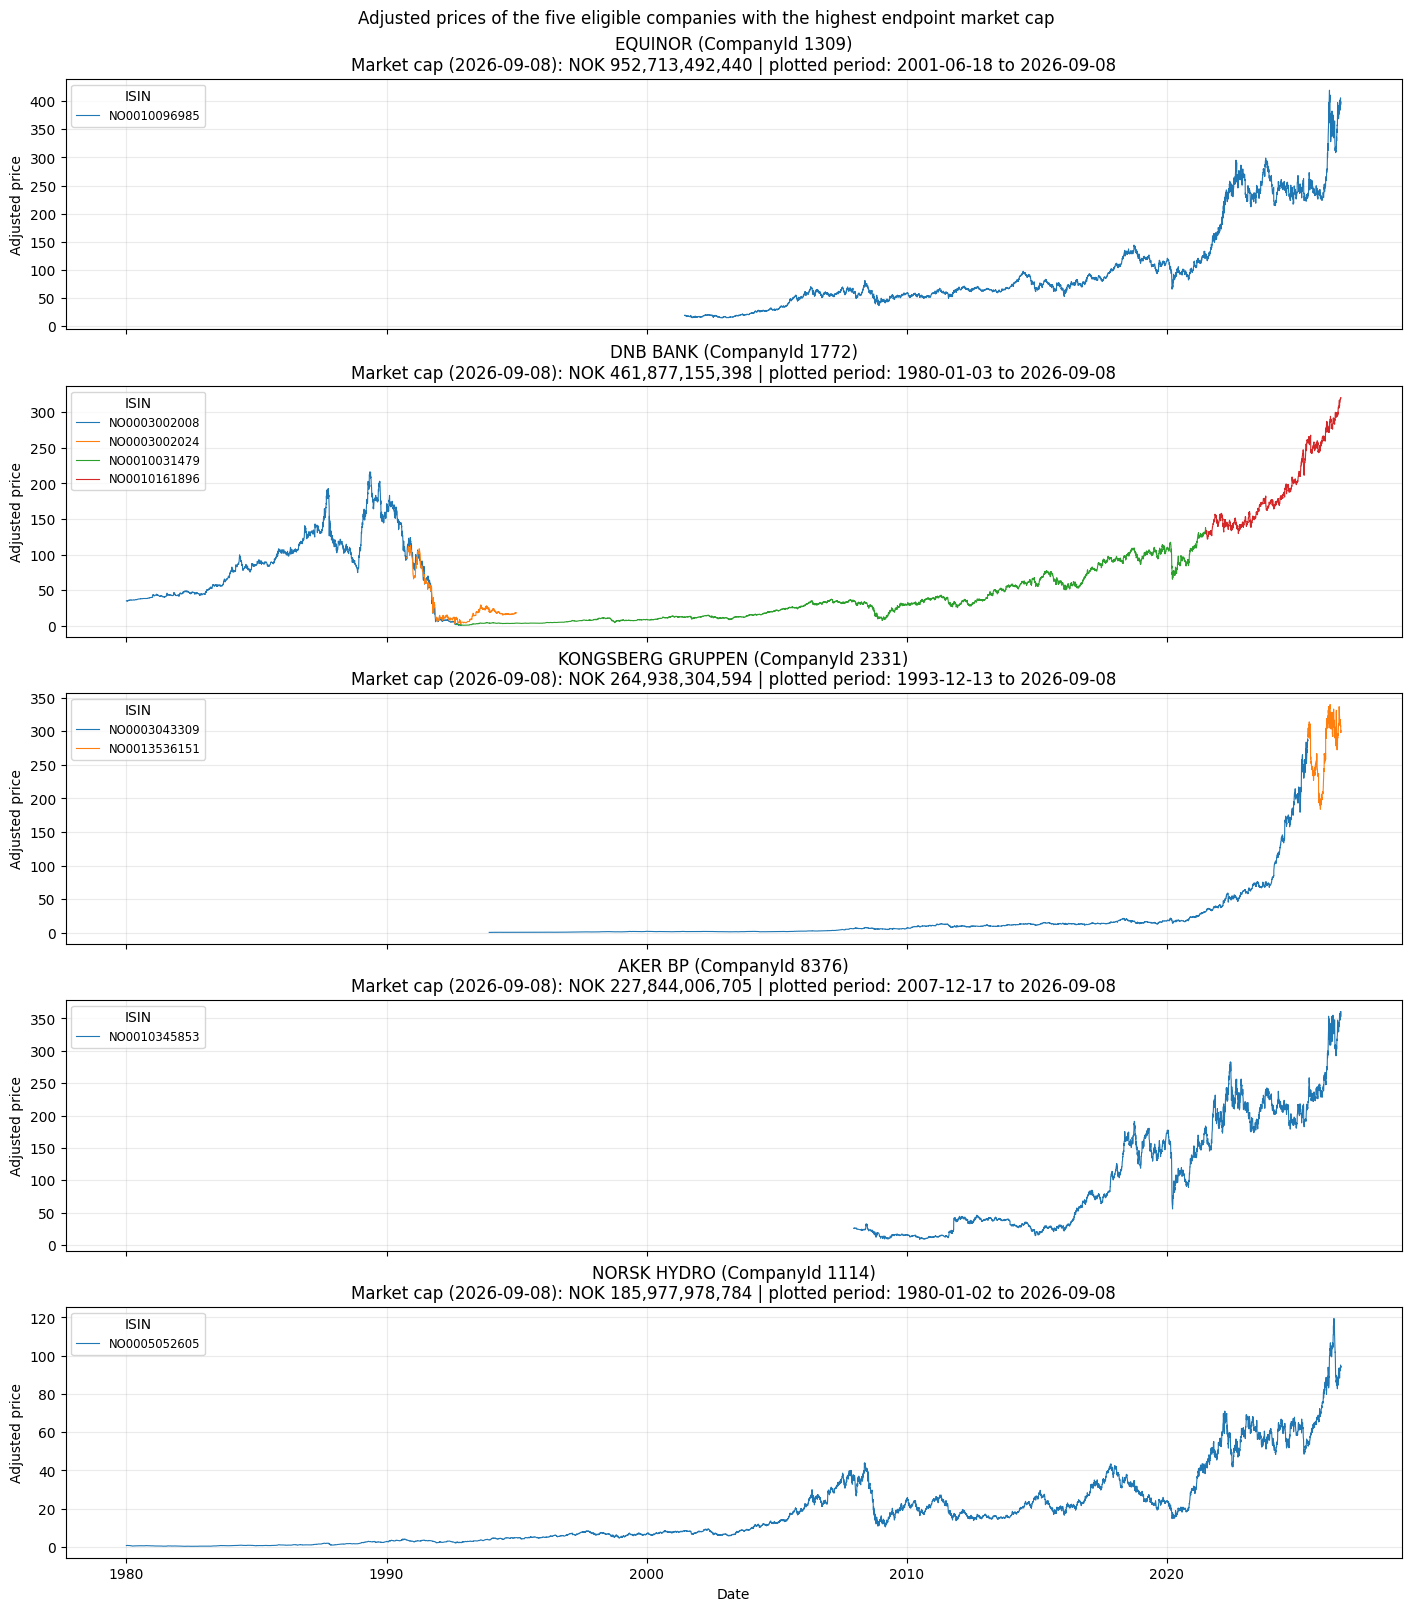

In [ ]:
import matplotlib.pyplot as plt

# Rank eligible companies by market cap at the dataset endpoint.
top_five = company_summary.head(5)
display(top_five)
print("Adjusted-price plots show all available ISINs separately for each CompanyId.")
print("Prices use the dataset's AdjustedPrice; zero and missing prices are omitted from the plots.")
print("Lines connect the remaining observations; omitted prices are not filled.")
print("AdjustedPrice = Price × CorpAdj × DividendAdj (corporate-action and dividend adjustment factors).")

fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True, constrained_layout=True)
for ax, (company_id, summary) in zip(axes, top_five.iterrows()):
    records = companies.get_group(company_id)
    for isin, security in records.groupby("ISIN", dropna=False, sort=False):
        series = security.set_index("Date")["AdjustedPrice"].replace(0, float("nan")).dropna()
        ax.plot(series.index, series, linewidth=0.8, label=isin if pd.notna(isin) else "Missing ISIN")
    ax.legend(title="ISIN", fontsize="small")
    ax.set_title(
        f"{summary['latest_name']} (CompanyId {company_id})\n"
        f"Market cap ({end_date:%Y-%m-%d}): NOK {summary['market_cap']:,.0f} | "
        f"plotted period: {records['Date'].min():%Y-%m-%d} to {records['Date'].max():%Y-%m-%d}"
    )
    ax.set_ylabel("Adjusted price")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Date")
fig.suptitle("Adjusted prices of the five eligible companies with the highest endpoint market cap")
plt.show()


In [ ]:
# Keep the sector labels supplied by the dataset; trim whitespace only.
sectors = data["Sector"].str.strip().replace("", pd.NA)
sector_names = sorted(sectors.dropna().unique())
print(f"Distinct sectors: {len(sector_names)}")
for sector in sector_names:
    print(f"- {sector}")

# company_data is sorted by date within each CompanyId.
# last() uses the latest nonmissing sector, including across name changes.
sector_records = company_data[["CompanyId", "Date"]].copy()
sector_records["Sector"] = sectors.loc[sector_records.index]
latest_sectors = sector_records.groupby("CompanyId")["Sector"].last()
sector_company_summary = company_summary.join(latest_sectors.rename("sector"))
print("Each company is assigned to its latest nonmissing recorded sector.")
print(f"Companies without a sector: {sector_company_summary['sector'].isna().sum():,}")
sector_counts = (
    sector_company_summary.groupby("sector").size().reindex(sector_names, fill_value=0)
    .rename("companies").to_frame()
)
display(sector_counts)


Distinct sectors: 16
- Bank
- Basic Materials
- Consumer Discretionary
- Consumer Staples
- ETF
- Energy
- Financials
- Health Care
- Industrials
- Information Technology
- Materials
- Real Estate
- Technology
- Telecom
- Telecommunications
- Utilities
Each company is assigned to its latest nonmissing recorded sector.
Companies without a sector: 0


,companies
sector,
Bank,0
Basic Materials,6
Consumer Discretionary,8
Consumer Staples,8
ETF,0
Energy,32
Financials,29
Health Care,7
Industrials,30


In [ ]:
# Rank sectors by the number of eligible CompanyId groups.
# Each company is assigned to its latest recorded sector.
sector_ranking = sector_company_summary.groupby("sector").agg(
    companies=("market_cap", "size"),
    total_market_cap=("market_cap", "sum"),
).sort_values("companies", ascending=False)
top_sectors = sector_ranking.head(5)
print("Top five sectors by number of eligible companies:")
display(top_sectors)

sector_top_companies = (
    sector_company_summary.loc[sector_company_summary["sector"].isin(top_sectors.index)]
    .sort_values("market_cap", ascending=False)
    .groupby("sector", sort=False).head(5)
)
display(sector_top_companies.sort_values(["sector", "market_cap"], ascending=[True, False]))


Top five sectors by number of eligible companies:


,companies,total_market_cap
sector,,
Energy,32,1.461690e+12
Industrials,30,6.893529e+11
Financials,29,1.108845e+12
Technology,14,1.321736e+11
Consumer Discretionary,8,4.797146e+10


,latest_name,start_date,end_date,observations,available_adjusted_prices,securities,total_volume,span_years,market_cap,sector
CompanyId,,,,,,,,,,
12441,EUROPRIS,2015-06-19,2026-09-08,2849,2849,1,8.221209e+08,11.222450,1.454299e+10,Consumer Discretionary
7628,NORWEGIAN AIR SHUT,2003-12-18,2026-09-08,5720,5720,1,2.712552e+10,22.724162,1.345430e+10,Consumer Discretionary
12737,SATS,2019-10-23,2026-09-08,1756,1756,1,4.590934e+08,6.877481,8.824458e+09,Consumer Discretionary
12451,KID,2015-11-02,2026-09-08,2730,2730,1,9.478455e+07,10.850103,4.942452e+09,Consumer Discretionary
8537,POLARIS MEDIA,2008-10-22,2026-09-08,2779,2779,1,5.868137e+06,17.878166,2.960187e+09,Consumer Discretionary
1309,EQUINOR,2001-06-18,2026-09-08,6363,6363,1,3.552889e+10,25.223819,9.527135e+11,Energy
8376,AKER BP,2007-12-17,2026-09-08,4460,4460,1,3.067855e+09,18.726899,2.278440e+11,Energy
6030,SUBSEA 7,1997-06-05,2026-09-08,7383,7383,3,7.959148e+09,29.259411,9.719024e+10,Energy
6070,TGS,1997-10-30,2026-09-08,7267,7267,1,3.299142e+09,28.856947,2.750430e+10,Energy


Companies are ranked by endpoint market cap; plots show adjusted prices.
Zero and missing prices are omitted; lines connect the remaining observations.
Each ISIN is plotted separately; different securities are not joined or adjusted further.


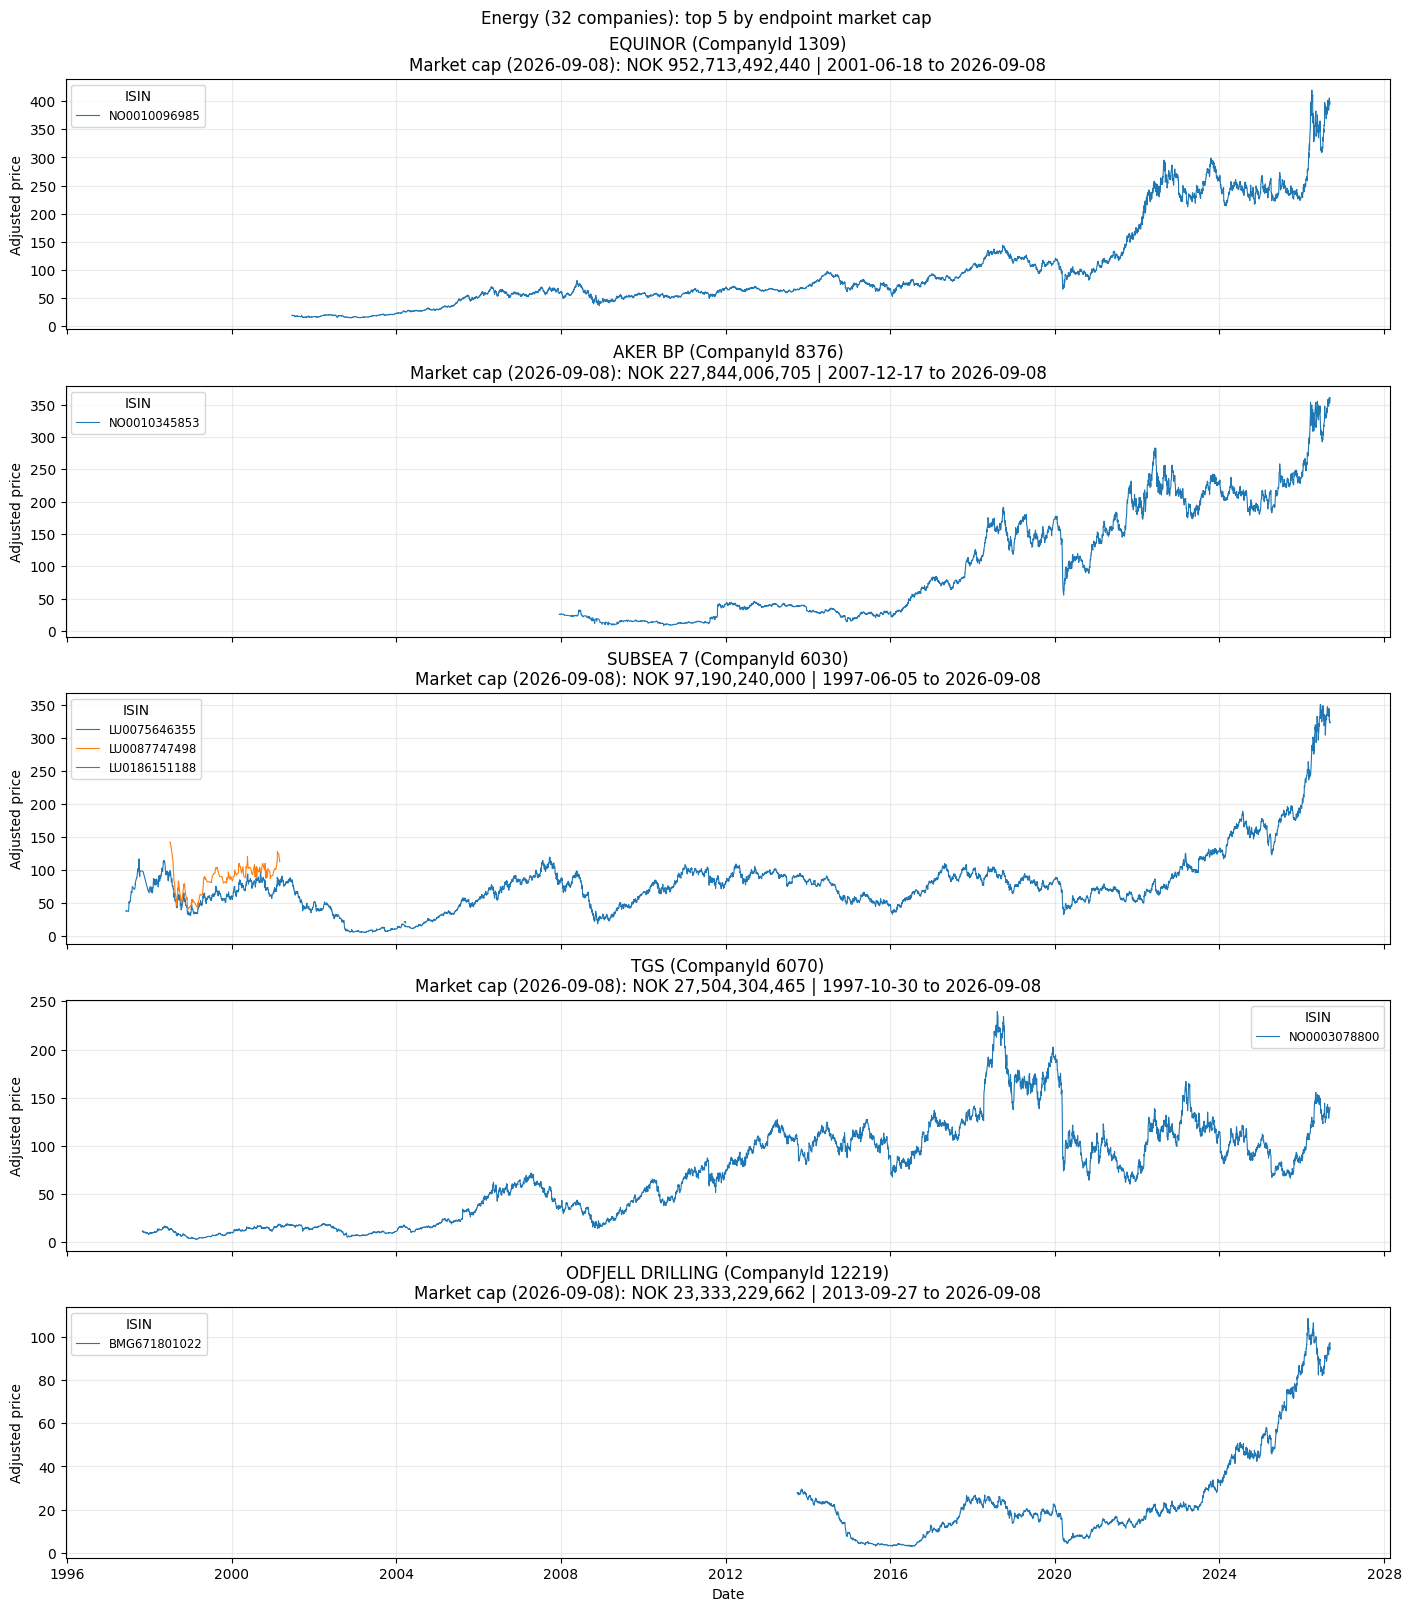

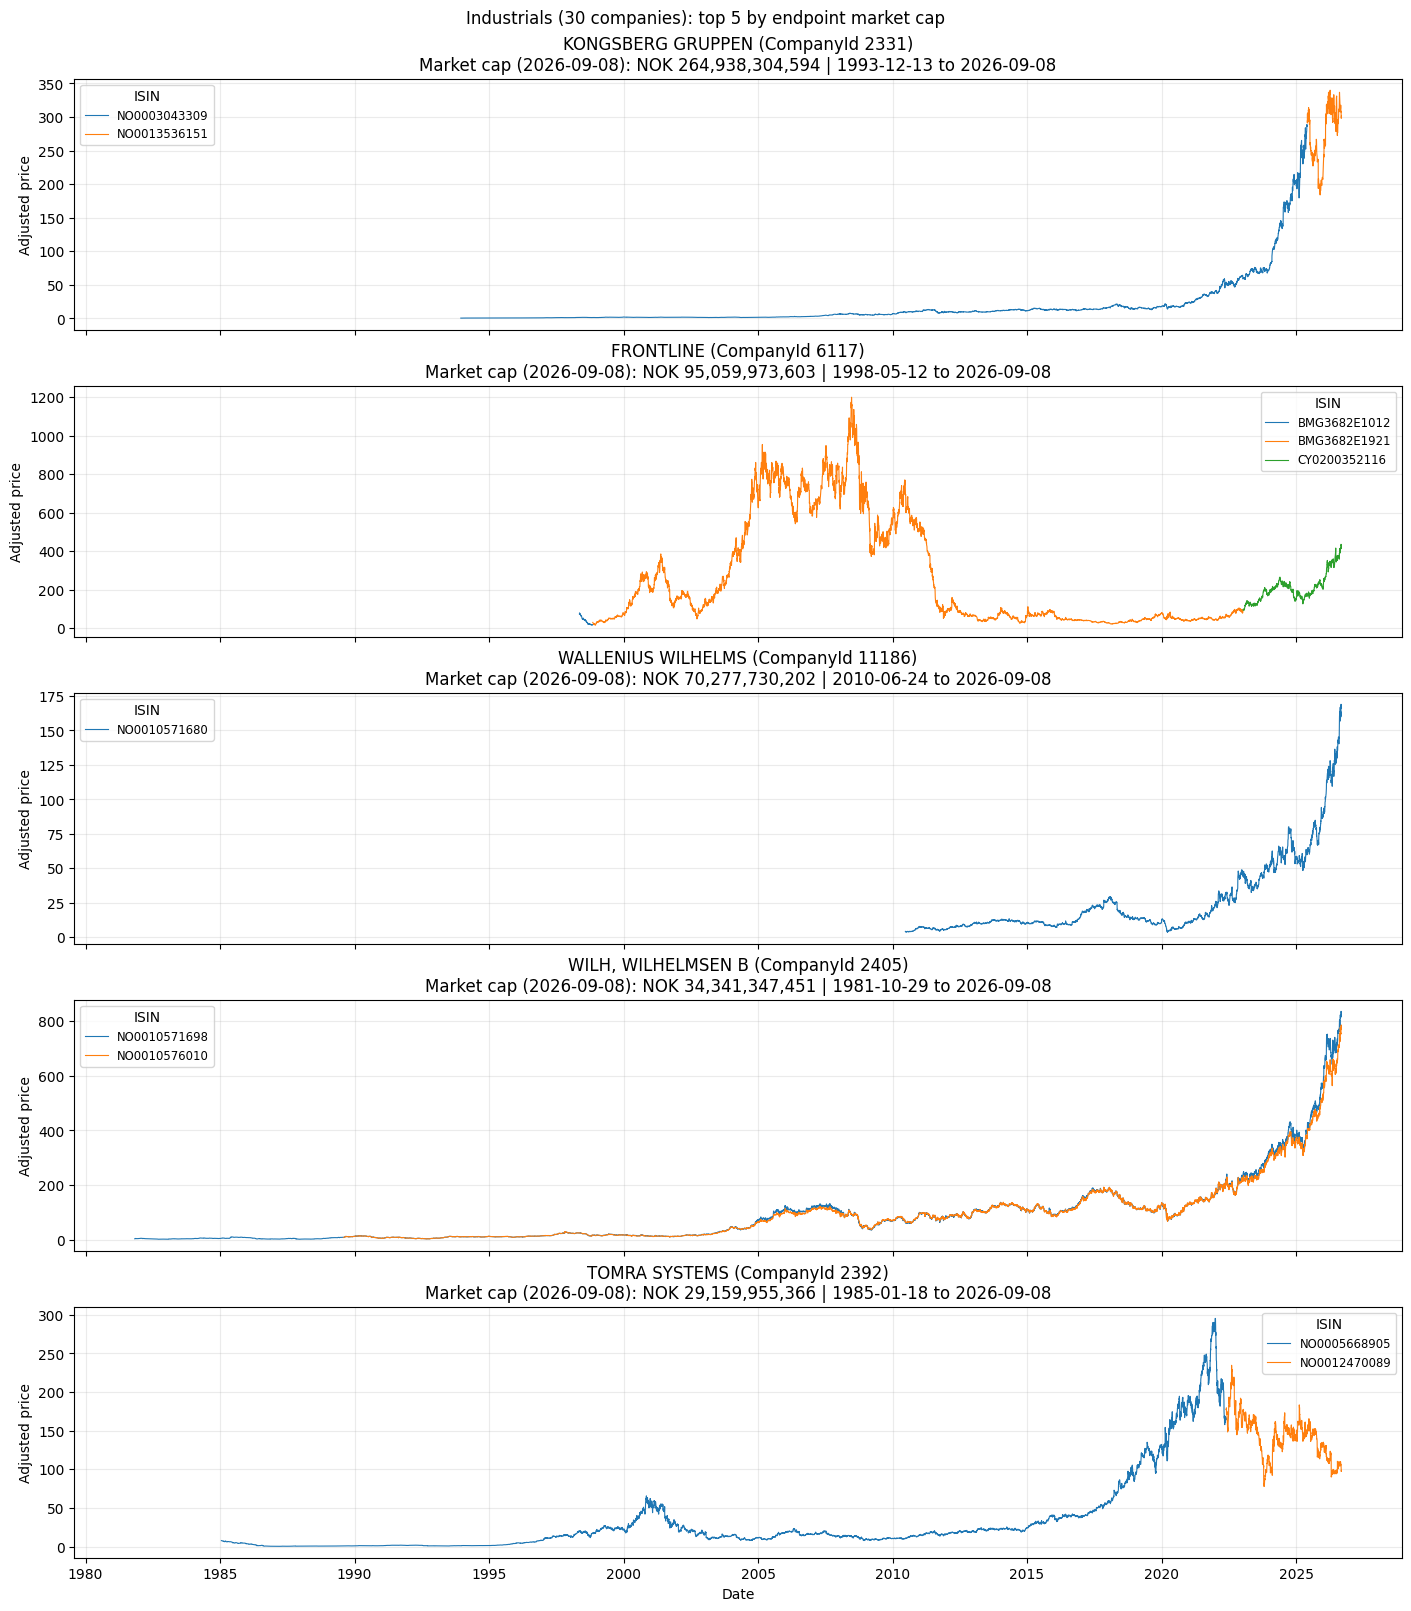

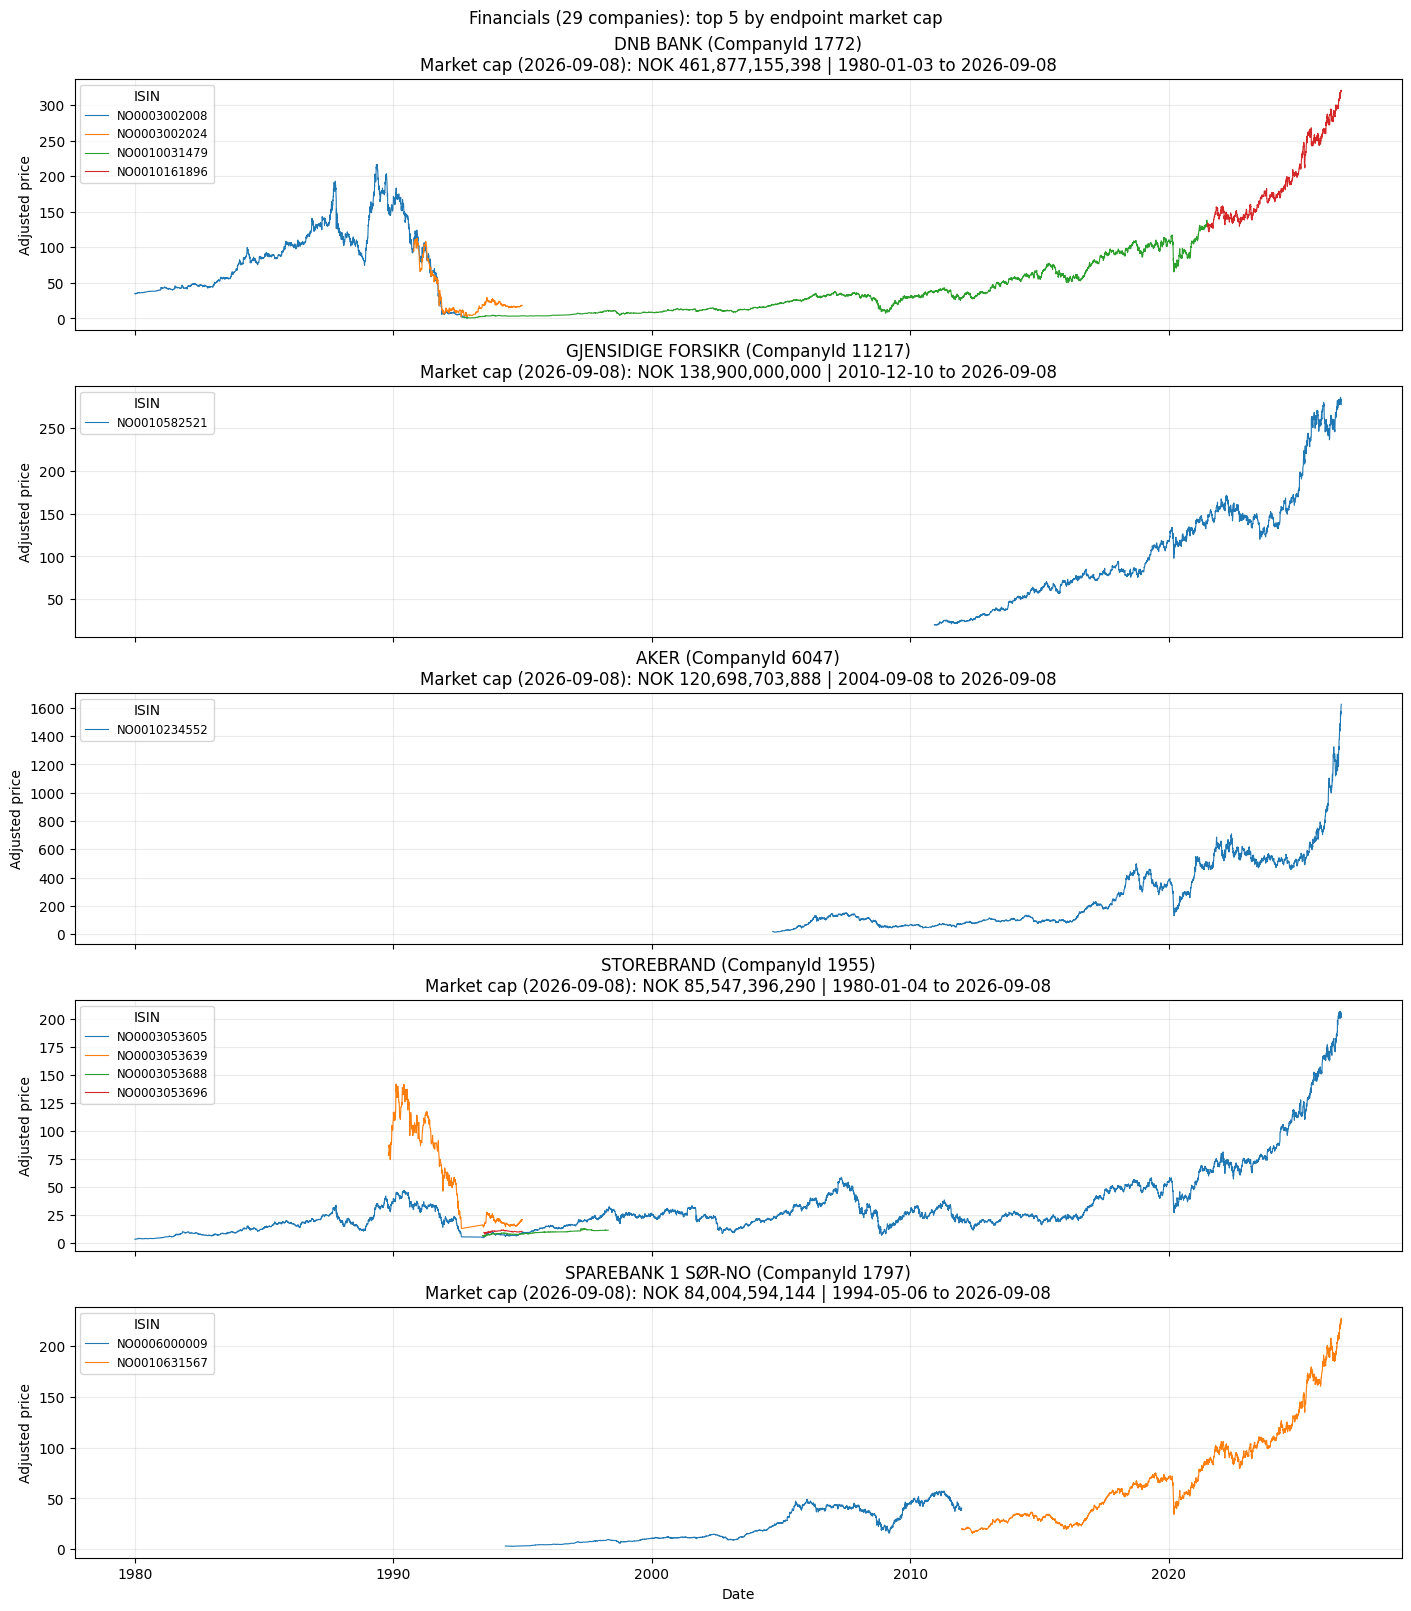

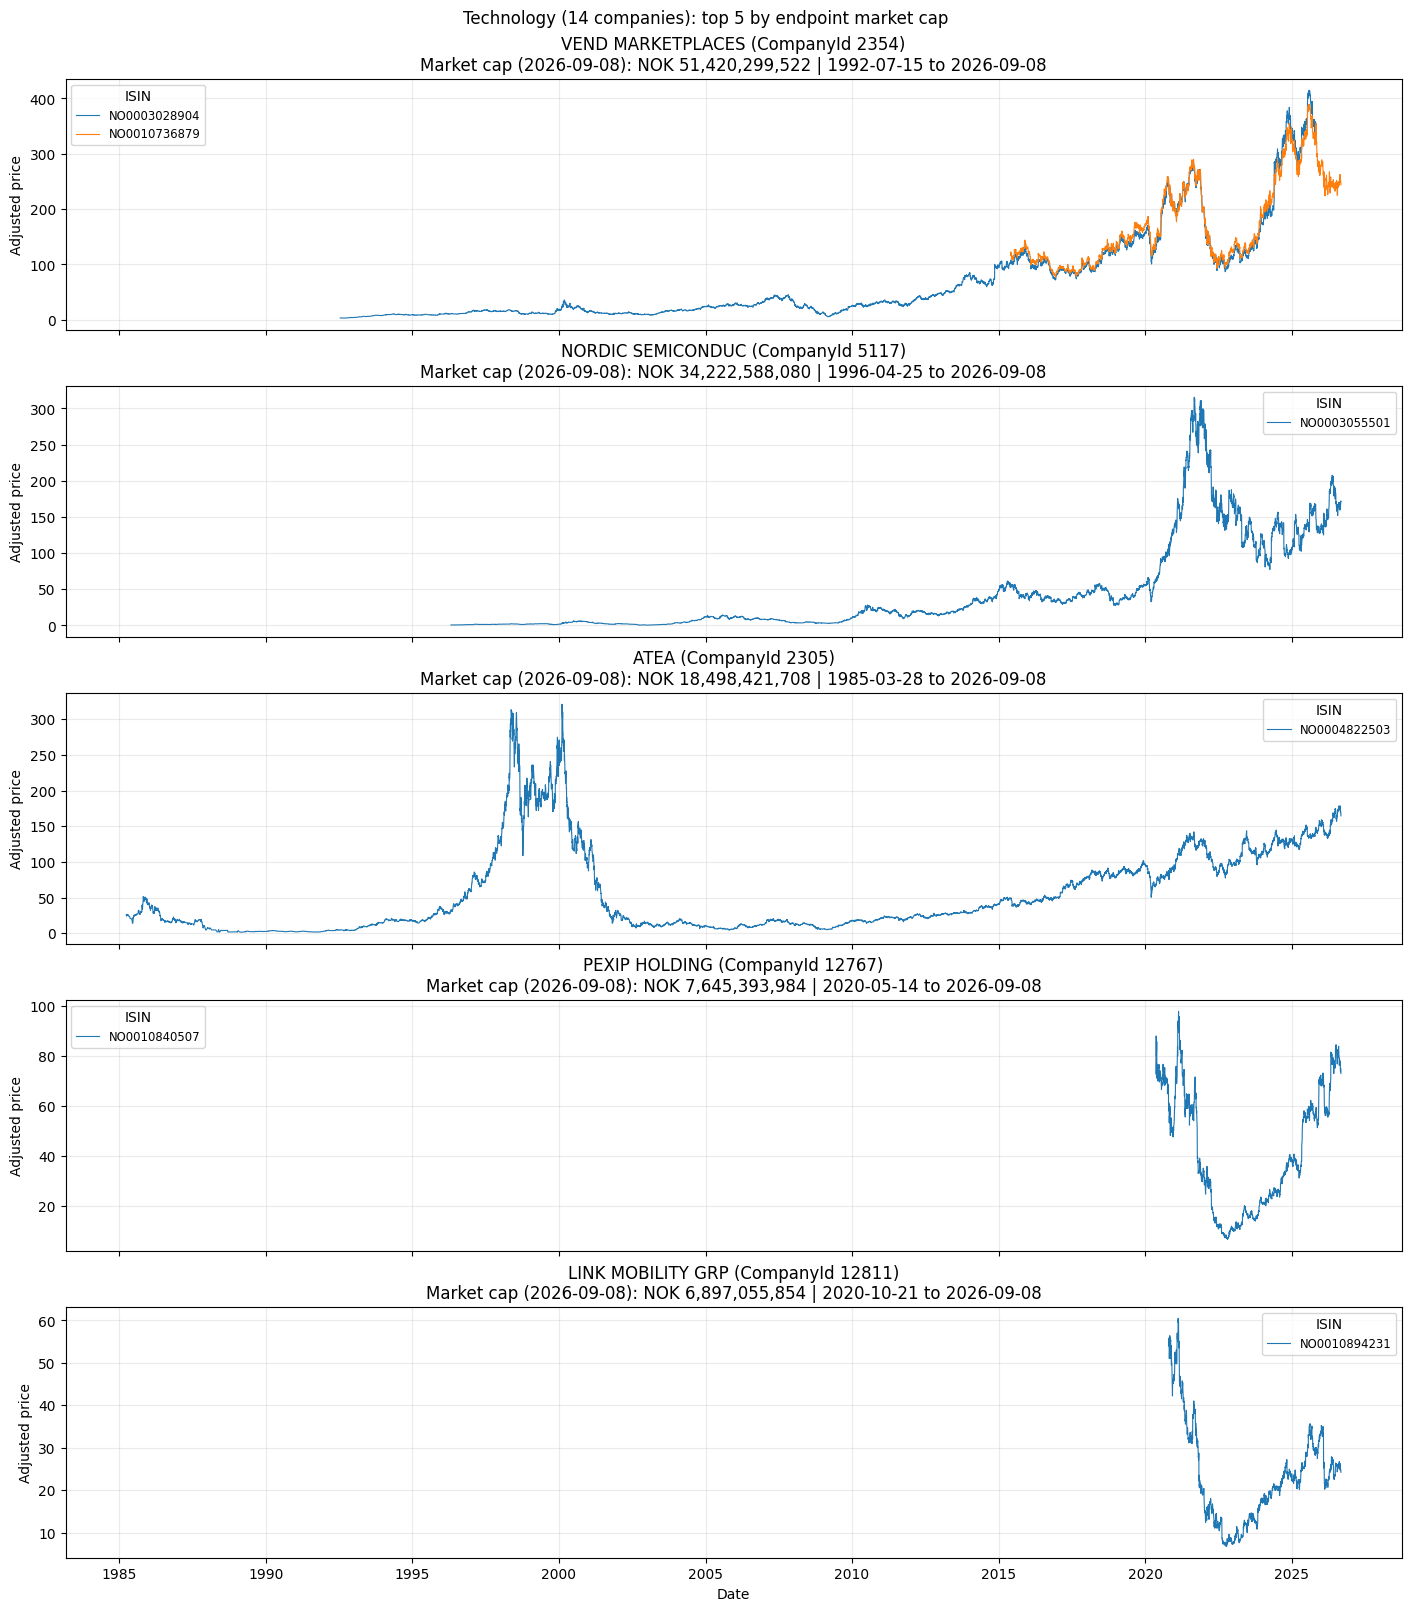

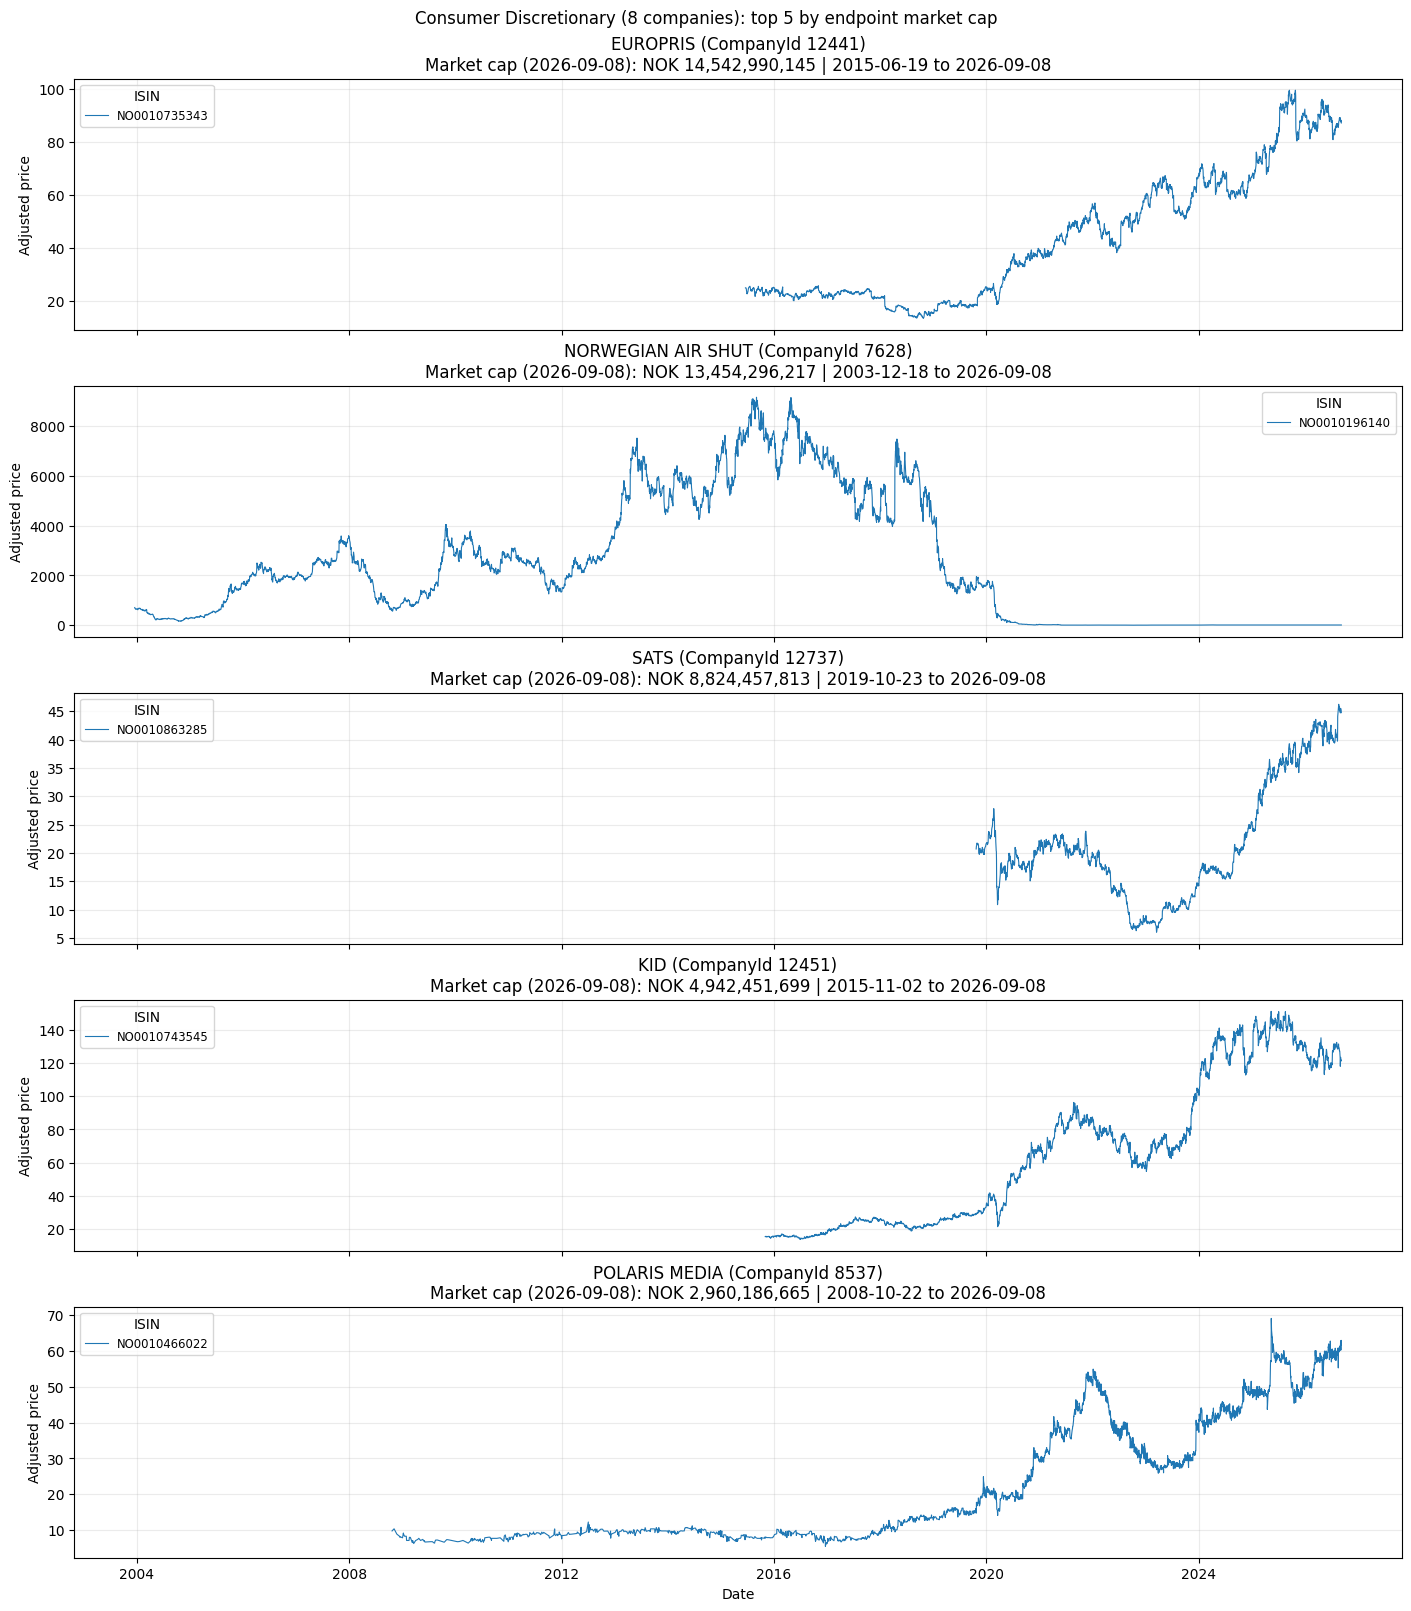

In [ ]:
print("Companies are ranked by endpoint market cap; plots show adjusted prices.")
print("Zero and missing prices are omitted; lines connect the remaining observations.")
print("Each ISIN is plotted separately; different securities are not joined or adjusted further.")

for sector in top_sectors.index:
    sector_top = sector_top_companies.loc[sector_top_companies["sector"] == sector]
    fig, axes = plt.subplots(
        len(sector_top), 1, figsize=(14, 3.2 * len(sector_top)),
        sharex=True, squeeze=False, constrained_layout=True,
    )
    for ax, (company_id, summary) in zip(axes[:, 0], sector_top.iterrows()):
        records = companies.get_group(company_id)
        for isin, security in records.groupby("ISIN", dropna=False, sort=False):
            series = security.set_index("Date")["AdjustedPrice"].replace(0, float("nan")).dropna()
            ax.plot(series.index, series, linewidth=0.8, label=isin if pd.notna(isin) else "Missing ISIN")
        ax.legend(title="ISIN", fontsize="small")
        ax.set_title(
            f"{summary['latest_name']} (CompanyId {company_id})\n"
            f"Market cap ({end_date:%Y-%m-%d}): NOK {summary['market_cap']:,.0f} | "
            f"{records['Date'].min():%Y-%m-%d} to {records['Date'].max():%Y-%m-%d}"
        )
        ax.set_ylabel("Adjusted price")
        ax.grid(alpha=0.25)
    axes[-1, 0].set_xlabel("Date")
    fig.suptitle(
        f"{sector} ({top_sectors.loc[sector, 'companies']:,.0f} companies): "
        f"top {len(sector_top)} by endpoint market cap"
    )
    plt.show()
    plt.close(fig)
